# Human Gender Recognition with PyTorch

This notebook converts a Keras CNN for gender recognition to PyTorch. It preserves the CNN + MLP architecture, 64 × 64 grayscale input, and training utilities: best-checkpoint saving, early stopping, learning-rate reduction, and TensorBoard logging.

## Workflow
1. Load the data and convert images to PyTorch channel order `[N, C, H, W]`.
2. Define the CNN and configure the loss and optimizer.
3. Train the model, monitor validation metrics, and save checkpoints.
4. Load a checkpoint, evaluate the model, and predict a sample image.

## 1. Import Libraries and Configure the Environment

In [1]:
import os
# Avoid loading a second OpenMP runtime from Anaconda's MKL beside PyTorch.
os.environ['MKL_THREADING_LAYER'] = 'SEQUENTIAL'

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter

cwd = Path.cwd()
utility_candidates = (
    cwd,
    *(parent / '4. Training Utilities' for parent in (cwd, *cwd.parents)),
    cwd / 'BTL03' / '4. Training Utilities',
)
notebook_dir = next(path for path in utility_candidates if (path / 'shared_training.py').is_file())
sys.path.insert(0, str(notebook_dir))
from shared_training import fit, run_epoch, seed_everything

seed_everything(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = 2
genders = ('female', 'male')
print(f'Device: {device}')

Device: cpu


## 2. Load the Data

Place the four `.npy` files alongside this notebook. The image arrays are initially in `[N, H, W, C]` format. As in the original Keras notebook, rotate the images and then convert them to `[N, C, H, W]`, the format expected by `Conv2d`. Keep pixel values in their original range and cast them to `float32`. Convert one-hot labels to class indices for `CrossEntropyLoss`.

In [2]:
def load_gender_data(image_file, label_file):
    images = np.load(notebook_dir / image_file)
    one_hot_labels = np.load(notebook_dir / label_file)
    if images.ndim != 4 or images.shape[1:] != (64, 64, 1):
        raise ValueError(f'Expected images with shape [N, 64, 64, 1], got {images.shape}.')
    if one_hot_labels.ndim != 2 or one_hot_labels.shape[1] != num_classes:
        raise ValueError(f'Expected one-hot labels with shape [N, 2], got {one_hot_labels.shape}.')
    if len(images) != len(one_hot_labels):
        raise ValueError('Image and label counts do not match.')

    images = np.rot90(images, k=3, axes=(1, 2))
    images = np.ascontiguousarray(images.transpose(0, 3, 1, 2), dtype=np.float32)
    labels = one_hot_labels.argmax(axis=1).astype(np.int64)
    return torch.from_numpy(images), torch.from_numpy(labels)


x_train, y_train = load_gender_data(
    '64_64_11938_4098_train_x_onehot.npy',
    '64_64_11938_4098_train_y_onehot.npy',
)
x_test, y_test = load_gender_data(
    '64_64_5968_4098_val_x_onehot.npy',
    '64_64_5968_4098_val_y_onehot.npy',
)

print(f'Train: {len(x_train)} images, shape {tuple(x_train.shape[1:])}')
print(f'Validation: {len(x_test)} images, shape {tuple(x_test.shape[1:])}')
print(f'Pixel range: {x_train.min().item():.0f}–{x_train.max().item():.0f}')

Train: 11938 images, shape (1, 64, 64)
Validation: 5968 images, shape (1, 64, 64)
Pixel range: 0–255


## 3. Define the CNN Model

The convolution, pooling, dropout, and fully connected layers retain the same counts and dimensions as the Keras model. After five pooling operations, the spatial dimensions are `2 × 2`, so `Flatten` produces `256 × 2 × 2 = 1024` features for the MLP. The model returns logits; no softmax is added because `CrossEntropyLoss` handles that internally.

In [3]:
class GenderCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 2 * 2, 1024), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(1024, 1024), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(1024, num_classes),
        )

        # Xavier uniform and zero bias match the Keras Dense/Conv2D defaults.
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, images):
        return self.classifier(self.features(images))


model = GenderCNN(num_classes).to(device)
print(model)
print(f'Trainable parameters: {sum(parameter.numel() for parameter in model.parameters()):,}')

GenderCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Dropout(p=0.2, inplace=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Dropout(p=0.2, inplace=False)
    (14): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU()
    (16): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (17): ReLU()
    (18): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1

## 4. Train the Model and Use Training Utilities

The `fit` function in `shared_training.py` runs the training and evaluation loops, saves the weights with the best `val_loss`, applies early stopping, and logs metrics. The scheduler reduces the learning rate when `val_loss` stops improving. After training, launch TensorBoard with `tensorboard --logdir logs`.

In [4]:
batch_size = 128
epochs = 100000
train_loader = DataLoader(
    TensorDataset(x_train, y_train),
    batch_size=batch_size,
    shuffle=True,
    pin_memory=device.type == 'cuda',
)
validation_loader = DataLoader(
    TensorDataset(x_test, y_test),
    batch_size=batch_size,
    pin_memory=device.type == 'cuda',
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, eps=1e-7)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.1, patience=5, min_lr=0.0001
)
checkpoint_path = notebook_dir / 'checkpoints' / 'best_gender_cnn.pth'
writer = SummaryWriter(log_dir=str(notebook_dir / 'logs'))

starting_time = time.time()
try:
    training_result = fit(
        model,
        train_loader,
        validation_loader,
        optimizer,
        criterion,
        device,
        epochs=epochs,
        checkpoint_path=checkpoint_path,
        patience=5,
        scheduler=scheduler,
        writer=writer,
    )
finally:
    writer.close()

print(f'Training time: {(time.time() - starting_time) / 60:.2f} minutes')
print(f"Best epoch: {training_result['best_epoch']}")
print(f"Best validation accuracy: {training_result['best_val_accuracy']:.2%}")
print(f'Checkpoint: {checkpoint_path}')

01/100000 train 0.5537 78.45% val 0.5116 78.85% lr 0.001
02/100000 train 0.5124 78.85% val 0.5088 78.85% lr 0.001
03/100000 train 0.5134 78.85% val 0.5114 78.85% lr 0.001
04/100000 train 0.5113 78.85% val 0.5097 78.85% lr 0.001
05/100000 train 0.5028 78.81% val 0.5196 78.85% lr 0.001
06/100000 train 0.4996 78.81% val 0.4990 78.85% lr 0.001
07/100000 train 0.4953 78.91% val 0.5071 78.85% lr 0.001
08/100000 train 0.4938 79.17% val 0.4953 78.85% lr 0.001
09/100000 train 0.4776 79.39% val 0.4885 79.04% lr 0.001
10/100000 train 0.4606 80.70% val 0.4375 82.37% lr 0.001
11/100000 train 0.4443 81.66% val 0.4341 82.74% lr 0.001
12/100000 train 0.4279 82.35% val 0.4171 82.98% lr 0.001
13/100000 train 0.4175 82.74% val 0.4065 83.81% lr 0.001
14/100000 train 0.4057 83.98% val 0.4301 82.04% lr 0.001
15/100000 train 0.4015 84.15% val 0.4156 84.00% lr 0.001
16/100000 train 0.3904 84.43% val 0.3994 83.98% lr 0.001
17/100000 train 0.3865 84.82% val 0.4057 83.60% lr 0.001
18/100000 train 0.3775 85.22% v

## 5. Load a Checkpoint and Evaluate

The validation set is used for evaluation, matching the original notebook. Run the training cell first to create the checkpoint.

In [5]:
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
model.eval()
score = run_epoch(model, validation_loader, criterion, device)
print('Validation loss:', score['loss'])
print('Validation accuracy:', score['accuracy'])

Validation loss: 0.32379800560646976
Validation accuracy: 0.880529490616622


## 6. Predict a Sample Image

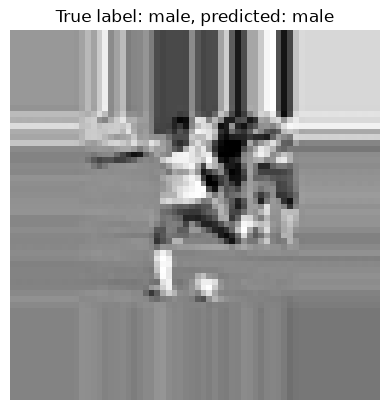

In [6]:
random_test_index = np.random.randint(len(x_test))
test_image = x_test[random_test_index]
test_label = y_test[random_test_index].item()

model.eval()
with torch.inference_mode():
    logits = model(test_image.unsqueeze(0).to(device))
    predicted_label = logits.argmax(dim=1).item()

plt.imshow(test_image[0].numpy(), cmap='gray')
plt.title(
    f'True label: {genders[test_label]}, predicted: {genders[predicted_label]}'
)
plt.axis('off')
plt.show()